# My Mr Clean
Building a simple search engine pipeline using the Wikipedia API.

## 1. Getting the Data

In [1]:
import requests
import re
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from collections import Counter
%matplotlib inline

def get_content(article_name):
    url = 'https://en.wikipedia.org/w/api.php'
    params = {
        'action': 'query',
        'titles': article_name,
        'prop': 'revisions',
        'rvprop': 'content',
        'rvslots': 'main',
        'formatversion': '2',
        'format': 'json'
    }
    headers = {'User-Agent': 'EncyclEarthpedia/1.0 (student project)'}
    response = requests.get(url, params=params, headers=headers)
    return response.json()

data = get_content('Ozone_layer')
print(data)

{'batchcomplete': True, 'query': {'normalized': [{'fromencoded': False, 'from': 'Ozone_layer', 'to': 'Ozone layer'}], 'pages': [{'pageid': 22834, 'ns': 0, 'title': 'Ozone layer', 'revisions': [{'slots': {'main': {'contentmodel': 'wikitext', 'contentformat': 'text/x-wiki', 'content': '{{Short description|Region of the stratosphere}}\n{{pp-semi-indef}}\n{{Use mdy dates|date=August 2023}}\n[[File:ISS041-E-105277 - View of the Northern Territory.jpg|thumb|The ozone layer visible from space at Earth\'s horizon as a blue band of [[afterglow]] within the bottom of the large bright blue band that is the [[stratosphere]], with a silhouette of a [[cumulonimbus]] in the orange afterglow of the [[troposphere]].]]\n\nThe \'\'\'ozone layer\'\'\' or \'\'\'ozone shield\'\'\' is a region of [[Earth]]\'s [[stratosphere]] that [[absorption (electromagnetic radiation)|absorbs]] most of the [[Sun]]\'s [[ultraviolet]] radiation. It contains a high concentration of [[ozone]] (O<sub>3</sub>) in relation to ot

## 2. Cleaning - merge_contents

In [2]:
def merge_contents(data):
    pages = data.get('query', {}).get('pages', [])
    raw_text = ''
    for page in pages:
        for rev in page.get('revisions', []):
            raw_text += rev.get('slots', {}).get('main', {}).get('content', '')
    for _ in range(5):
        raw_text = re.sub(r'\{\{[^{}]*\}\}', ' ', raw_text)
    raw_text = re.sub(r'\[\[(?:File|Image):[^\]]*\]\]', ' ', raw_text, flags=re.IGNORECASE)
    raw_text = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]+)\]\]', r'\1', raw_text)
    raw_text = re.sub(r'<ref[^>]*>.*?</ref>', ' ', raw_text, flags=re.DOTALL)
    raw_text = re.sub(r'<ref[^/]*/>', ' ', raw_text)
    raw_text = re.sub(r'<[^>]+>', ' ', raw_text)
    raw_text = re.sub(r'https?://\S+', ' ', raw_text)
    raw_text = re.sub(r'&\w+;', ' ', raw_text)
    raw_text = re.sub(r'=+[^=]+=+', ' ', raw_text)
    raw_text = re.sub(r"[^a-zA-Z0-9\s\-']", ' ', raw_text)
    raw_text = re.sub(r'\s+', ' ', raw_text).strip()
    return [raw_text]

merge_content = merge_contents(data)
print(merge_content[0][:300])

within the bottom of the large bright blue band that is the stratosphere with a silhouette of a cumulonimbus in the orange afterglow of the troposphere The '''ozone layer''' or '''ozone shield''' is a region of Earth's stratosphere that absorbs most of the Sun's ultraviolet radiation It contains a h


## 3. Tokenization

In [3]:
splitters = [' ', '\n', '\t', '-', '_', '/']

def tokenize(content):
    pattern = '|'.join(re.escape(s) for s in splitters)
    tokens = []
    for text in content:
        parts = re.split(pattern, text)
        tokens.extend([p for p in parts if p])
    return tokens

collection = tokenize(merge_content)
print(f'Total tokens: {len(collection)}')
print(collection[:20])

Total tokens: 2499
['within', 'the', 'bottom', 'of', 'the', 'large', 'bright', 'blue', 'band', 'that', 'is', 'the', 'stratosphere', 'with', 'a', 'silhouette', 'of', 'a', 'cumulonimbus', 'in']


## 4. Lowercase

In [4]:
def lower_collection(collection):
    collection[:] = [w.lower() for w in collection]
    return collection

lower_collection(collection)
print(collection[:20])

['within', 'the', 'bottom', 'of', 'the', 'large', 'bright', 'blue', 'band', 'that', 'is', 'the', 'stratosphere', 'with', 'a', 'silhouette', 'of', 'a', 'cumulonimbus', 'in']


## 5. Term Frequency

In [5]:
def count_frequency(collection):
    clean = [w for w in collection if w and not w.isdigit()]
    return Counter(clean)

def print_most_frequent(frequencies, n):
    print(f"{'Word':<25} {'Count':>6}")
    print('-' * 33)
    for word, count in frequencies.most_common(n):
        print(f'{word:<25} {count:>6}')

frequencies = count_frequency(collection)
print_most_frequent(frequencies, 10)

Word                       Count
---------------------------------
the                          201
of                            95
ozone                         85
in                            65
to                            60
and                           60
is                            39
a                             37
layer                         30
by                            29


## 6. Visualizing - Top 20 Most Frequent Words (unfiltered)

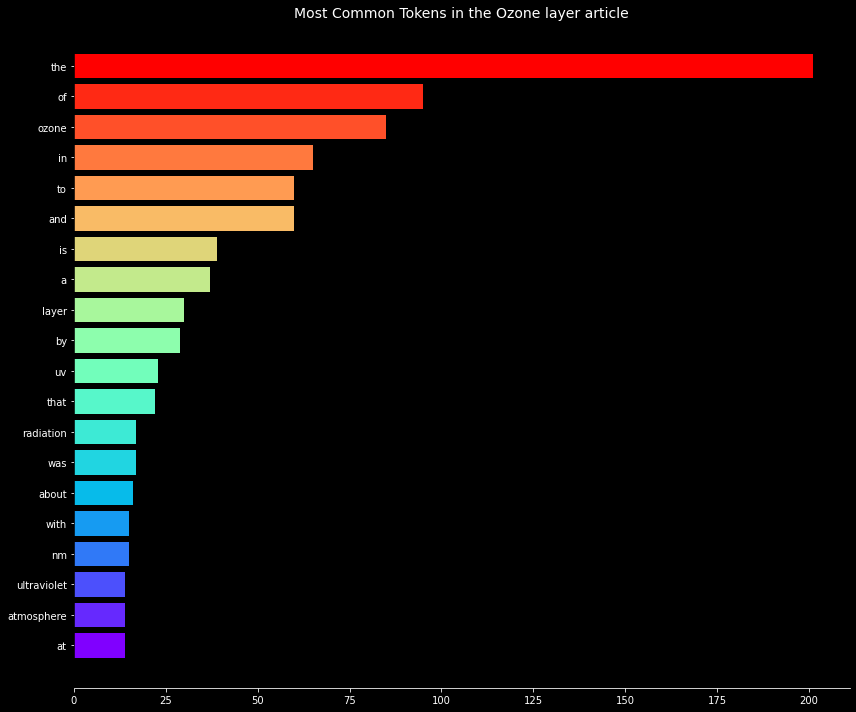

In [6]:
def plot_most_frequent(frequencies, n, title):
    top = frequencies.most_common(n)
    words = [w for w, c in top]
    counts = [c for w, c in top]
    # reverse so highest is on top
    words = words[::-1]
    counts = counts[::-1]
    colors = cm.rainbow(np.linspace(0, 1, len(words)))
    fig, ax = plt.subplots(figsize=(12, 10))
    fig.patch.set_facecolor('black')
    ax.set_facecolor('black')
    bars = ax.barh(words, counts, color=colors)
    ax.set_title(title, color='white', fontsize=14)
    ax.set_xlabel('', color='white')
    ax.tick_params(colors='white')
    ax.spines['bottom'].set_color('white')
    ax.spines['top'].set_color('black')
    ax.spines['left'].set_color('black')
    ax.spines['right'].set_color('black')
    plt.tight_layout()
    plt.show()

plot_most_frequent(frequencies, 20, 'Most Common Tokens in the Ozone layer article')

## 7. Filtering - Stop Words

In [7]:
stop_words = [
    'the', 'a', 'an', 'of', 'to', 'in', 'and', 'is', 'it', 'its',
    'was', 'are', 'be', 'by', 'as', 'at', 'or', 'for', 'on', 'from',
    'that', 'this', 'with', 'which', 'not', 'has', 'have', 'been',
    'but', 'also', 'can', 'more', 'than', 'into', 'their', 'they',
    'about', 'were', 'had', 'he', 'she', 'we', 'you', 'i', 's',
    'such', 'some', 'other', 'no', 'most', 'will', 'may', 'up',
    'so', 'while', 'between', 'through', 'during', 'under', 'over',
    'however', 'if', 'when', 'after', 'before', 'although', 'since',
    'all', 'any', 'both', 'each', 'few', 'many', 'new', 'these',
    'those', 'then', 'there', 'where', 'what', 'how', 'do', 'did',
    'does', 'use', 'used', 'using', 'would', 'could', 'should',
    'being', 'due', 'only', 'very', 'much', 'well', 'make', 'made',
    'one', 'two', 'three', 'first', 'second', 'per', 'km', 'nm', 'cm'
]

def remove_stop_words(words, stop_words):
    stop_set = set(stop_words)
    return [w for w in words if w not in stop_set and len(w) > 1]

filtered_collection = remove_stop_words(collection, stop_words)
print(f'Tokens after filtering: {len(filtered_collection)}')

Tokens after filtering: 1397


## 8. Visualizing - Top 25 Most Frequent Words (filtered)

Word                       Count
---------------------------------
ozone                         85
layer                         30
uv                            23
radiation                     17
ultraviolet                   14
atmosphere                    14
stratosphere                  11
surface                       11
earth's                       10
oxygen                        10


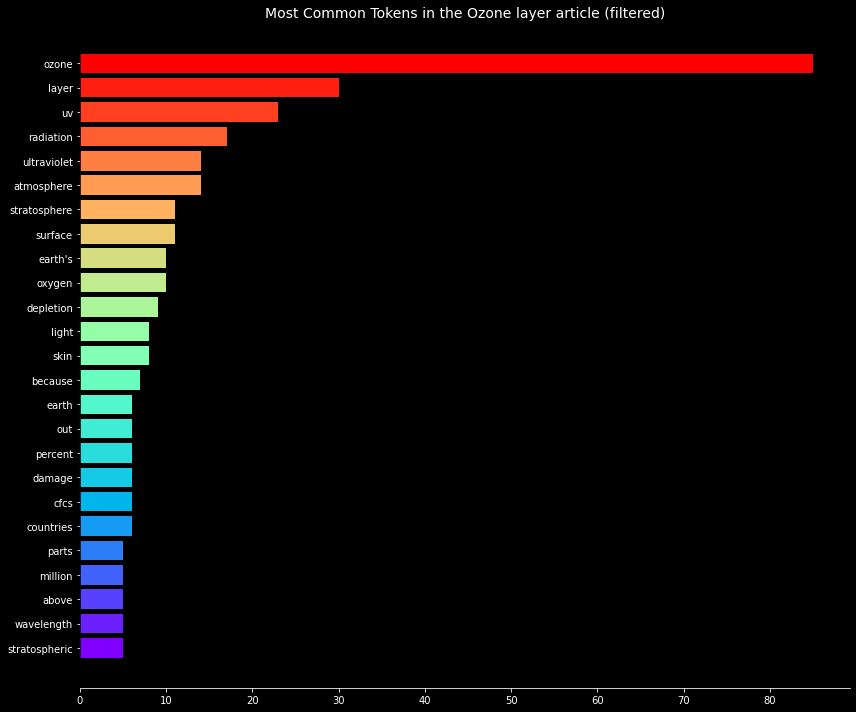

In [8]:
filtered_frequencies = count_frequency(filtered_collection)
print_most_frequent(filtered_frequencies, 10)
plot_most_frequent(filtered_frequencies, 25, 'Most Common Tokens in the Ozone layer article (filtered)')